# Test Set Visualization

This notebook visualizes samples from the test dataset.

**Purpose:**
- Browse and visualize test samples
- Find samples with power lines and pylons
- Understand class distribution
- Generate visualizations for presentations

**Classes:**
- Class 0: High Vegetation (Green)
- Class 1: Power Lines (Orange) ⚡
- Class 2: Pylons (Blue) 🗼
- Class 3: Others (Gray)

## 1. Setup and Imports

In [11]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from pathlib import Path
import json
from tqdm import tqdm

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 2. Configuration

In [12]:
# Configuration
CONFIG = {
    'data_dir': '../data/processed_data_optimized',
    'output_dir': 'test_visualizations',
    'num_samples': 20,  # Number of samples to visualize
    'samples_per_page': 1,  # Samples per figure
    'save_images': True,
    'dpi': 150,
    'filter_by_class': None,  # None, 'powerlines', 'pylons', or 'both'
}

# Class information
CLASS_NAMES = ['High Vegetation', 'Power Lines', 'Pylons', 'Others']
CLASS_COLORS = ['darkgreen', 'orange', 'blue', 'gray']

# Create output directory
Path(CONFIG['output_dir']).mkdir(exist_ok=True)

print("Configuration loaded!")
print(f"Data directory: {CONFIG['data_dir']}")
print(f"Output directory: {CONFIG['output_dir']}")
print(f"Number of samples to visualize: {CONFIG['num_samples']}")

Configuration loaded!
Data directory: ../data/processed_data_optimized
Output directory: test_visualizations
Number of samples to visualize: 20


## 3. Load Test Dataset

In [13]:
# Get test samples
test_dir = Path(CONFIG['data_dir']) / 'test'
test_samples = sorted(list(test_dir.glob('*.pt')))

print(f"Found {len(test_samples)} test samples")

# Load metadata
metadata_path = Path(CONFIG['data_dir']) / 'metadata.json'
if metadata_path.exists():
    with open(metadata_path) as f:
        metadata = json.load(f)
        print(f"\nMetadata:")
        print(f"  Classes: {metadata['n_classes']}")
        print(f"  Class names: {metadata['class_names']}")
        print(f"  Train samples: {metadata['n_train']}")
        print(f"  Test samples: {metadata['n_test']}")

Found 6203 test samples

Metadata:
  Classes: 4
  Class names: ['High Vegetation', 'Power Lines', 'Pylons', 'Others']
  Train samples: 24808
  Test samples: 6203


## 4. Analyze Class Distribution

In [14]:
print("Analyzing test set class distribution...\n")

# Analyze subset of samples
num_to_analyze = min(100, len(test_samples))
class_counts = np.zeros(4)
samples_with_powerlines = []
samples_with_pylons = []
samples_with_both = []

for idx in tqdm(range(num_to_analyze), desc="Analyzing samples"):
    sample = torch.load(test_samples[idx], weights_only=False)
    labels = sample['semantic_labels'].squeeze() - 1  # Convert to 0-indexed
    
    # Count classes
    for cls in range(4):
        class_counts[cls] += (labels == cls).sum().item()
    
    # Track samples with power infrastructure
    has_powerlines = (labels == 1).sum() > 10
    has_pylons = (labels == 2).sum() > 5
    
    if has_powerlines:
        samples_with_powerlines.append(idx)
    if has_pylons:
        samples_with_pylons.append(idx)
    if has_powerlines and has_pylons:
        samples_with_both.append(idx)

# Display results
total_points = class_counts.sum()
print(f"\nClass distribution (from {num_to_analyze} samples):")
for i, name in enumerate(CLASS_NAMES):
    count = class_counts[i]
    pct = 100 * count / total_points
    print(f"  {name}: {int(count):,} points ({pct:.2f}%)")

print(f"\nSamples with power infrastructure:")
print(f"  With power lines: {len(samples_with_powerlines)}")
print(f"  With pylons: {len(samples_with_pylons)}")
print(f"  With both: {len(samples_with_both)}")

Analyzing test set class distribution...



Analyzing samples: 100%|██████████| 100/100 [00:00<00:00, 1073.03it/s]


Class distribution (from 100 samples):
  High Vegetation: 219,366 points (58.84%)
  Power Lines: 646 points (0.17%)
  Pylons: 0 points (0.00%)
  Others: 152,822 points (40.99%)

Samples with power infrastructure:
  With power lines: 4
  With pylons: 0
  With both: 0


## 5. Select Samples to Visualize

In [15]:
# Select samples based on filter
if CONFIG['filter_by_class'] == 'powerlines':
    selected_indices = samples_with_powerlines[:CONFIG['num_samples']]
    print(f"Selected {len(selected_indices)} samples with power lines")
elif CONFIG['filter_by_class'] == 'pylons':
    selected_indices = samples_with_pylons[:CONFIG['num_samples']]
    print(f"Selected {len(selected_indices)} samples with pylons")
elif CONFIG['filter_by_class'] == 'both':
    selected_indices = samples_with_both[:CONFIG['num_samples']]
    print(f"Selected {len(selected_indices)} samples with both power lines and pylons")
else:
    # Random selection
    selected_indices = np.random.choice(
        len(test_samples), 
        min(CONFIG['num_samples'], len(test_samples)), 
        replace=False
    )
    print(f"Selected {len(selected_indices)} random samples")

print(f"Sample indices: {selected_indices.tolist() if hasattr(selected_indices, 'tolist') else selected_indices}")

Selected 20 random samples
Sample indices: [1839, 4422, 2916, 3062, 4626, 1805, 4875, 1800, 3512, 2085, 1086, 661, 5452, 150, 2735, 2836, 975, 4163, 5382, 3372]


## 6. Visualization Function

In [16]:
def visualize_sample(sample_idx, sample_data, save_path=None):
    """
    Create detailed 3D visualization of a single sample
    """
    points = sample_data['input_pcd'].numpy()
    labels = (sample_data['semantic_labels'].squeeze() - 1).numpy()  # Convert to 0-indexed
    
    # Create figure
    fig = plt.figure(figsize=(20, 6))
    fig.suptitle(f'Test Sample {sample_idx}', fontsize=16, fontweight='bold')
    
    # Calculate class statistics
    class_stats = {}
    for i in range(4):
        count = (labels == i).sum()
        class_stats[CLASS_NAMES[i]] = count
    
    # Full view
    ax1 = fig.add_subplot(131, projection='3d')
    ax1.set_title('Full Point Cloud', fontsize=12, fontweight='bold')
    for cls in range(4):
        mask = labels == cls
        if mask.sum() > 0:
            size = 20 if cls in [1, 2] else 1
            ax1.scatter(points[mask, 0], points[mask, 1], points[mask, 2],
                       c=CLASS_COLORS[cls], label=f"{CLASS_NAMES[cls]} ({mask.sum()})", 
                       s=size, alpha=0.7)
    ax1.legend(loc='upper right', fontsize=9)
    ax1.set_xlabel('X')
    ax1.set_ylabel('Y')
    ax1.set_zlabel('Z')
    
    # Power Lines Focus
    ax2 = fig.add_subplot(132, projection='3d')
    ax2.set_title('Power Lines (Orange)', fontsize=12, fontweight='bold', color='orange')
    powerline_mask = labels == 1
    if powerline_mask.sum() > 0:
        # Power lines
        ax2.scatter(points[powerline_mask, 0], points[powerline_mask, 1], 
                   points[powerline_mask, 2], c='orange', s=25, alpha=0.9, label='Power Lines')
        # Context (vegetation)
        veg_mask = labels == 0
        if veg_mask.sum() > 0:
            sample_size = min(3000, veg_mask.sum())
            sample_veg = np.random.choice(np.where(veg_mask)[0], sample_size, replace=False)
            ax2.scatter(points[sample_veg, 0], points[sample_veg, 1], 
                       points[sample_veg, 2], c='lightgreen', s=1, alpha=0.15, label='Vegetation (context)')
        ax2.legend(loc='upper right', fontsize=9)
    else:
        ax2.text(0.5, 0.5, 0.5, 'No power lines\nin this sample', 
                ha='center', va='center', fontsize=12, transform=ax2.transAxes)
    ax2.set_xlabel('X')
    ax2.set_ylabel('Y')
    ax2.set_zlabel('Z')
    
    # Pylons Focus
    ax3 = fig.add_subplot(133, projection='3d')
    ax3.set_title('Pylons (Blue)', fontsize=12, fontweight='bold', color='blue')
    pylon_mask = labels == 2
    if pylon_mask.sum() > 0:
        # Pylons
        ax3.scatter(points[pylon_mask, 0], points[pylon_mask, 1], 
                   points[pylon_mask, 2], c='blue', s=40, alpha=0.9, marker='^', label='Pylons')
        # Context
        context_mask = (labels == 0) | (labels == 1)
        if context_mask.sum() > 0:
            sample_size = min(2000, context_mask.sum())
            sample_ctx = np.random.choice(np.where(context_mask)[0], sample_size, replace=False)
            ctx_colors = ['lightgreen' if labels[i] == 0 else 'lightsalmon' for i in sample_ctx]
            ax3.scatter(points[sample_ctx, 0], points[sample_ctx, 1], 
                       points[sample_ctx, 2], c=ctx_colors, s=1, alpha=0.15, label='Context')
        ax3.legend(loc='upper right', fontsize=9)
    else:
        ax3.text(0.5, 0.5, 0.5, 'No pylons\nin this sample', 
                ha='center', va='center', fontsize=12, transform=ax3.transAxes)
    ax3.set_xlabel('X')
    ax3.set_ylabel('Y')
    ax3.set_zlabel('Z')
    
    # Add statistics text
    stats_text = "\n".join([f"{name}: {count}" for name, count in class_stats.items()])
    fig.text(0.02, 0.02, stats_text, fontsize=10, family='monospace',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=CONFIG['dpi'], bbox_inches='tight')
        print(f"Saved: {save_path}")
    
    plt.show()
    
print("Visualization function ready!")

Visualization function ready!


## 7. Generate Visualizations

Generating visualizations for 20 samples...


Visualizing sample 1/20 (index: 1839)
Saved: test_visualizations/sample_001839.png


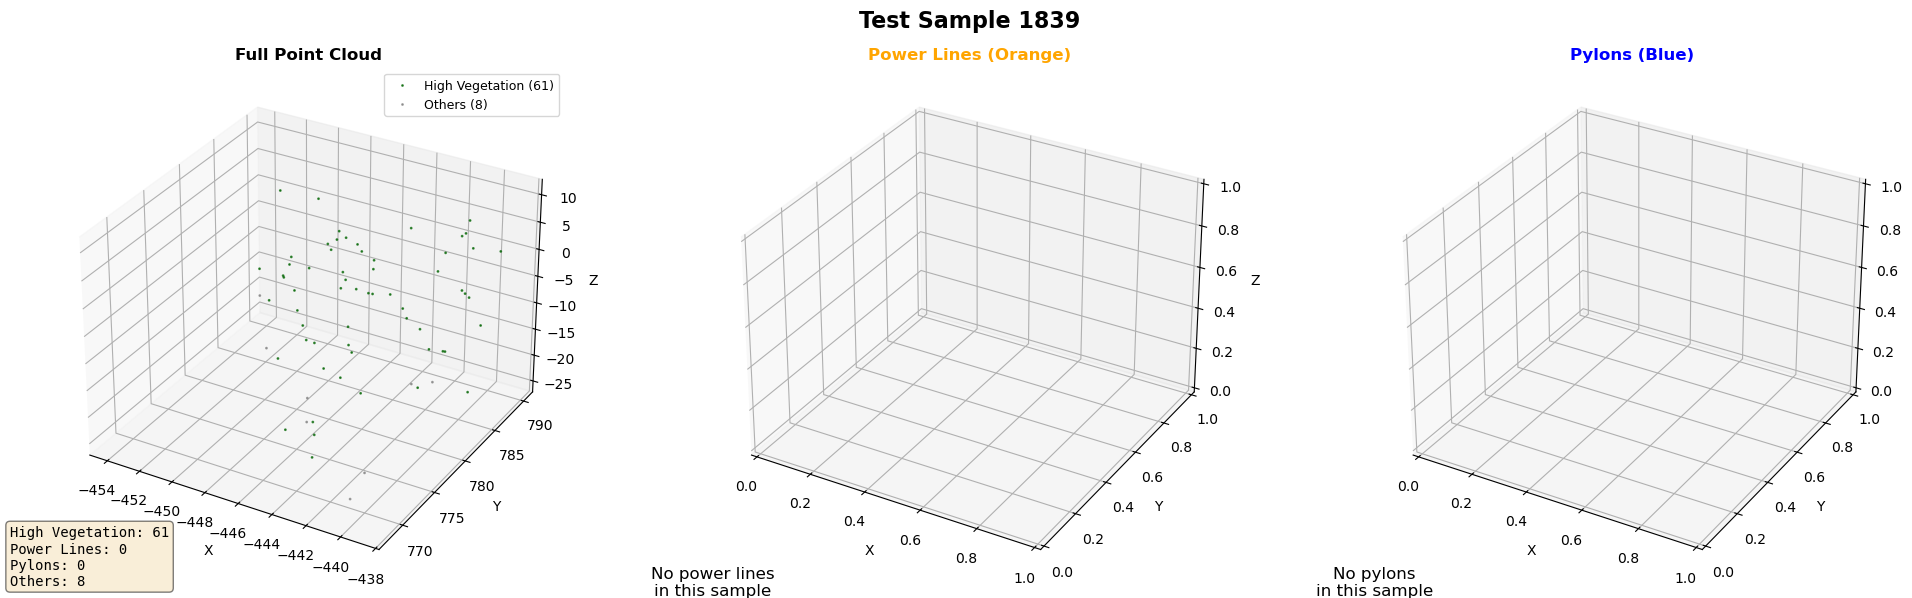


Visualizing sample 2/20 (index: 4422)
Saved: test_visualizations/sample_004422.png


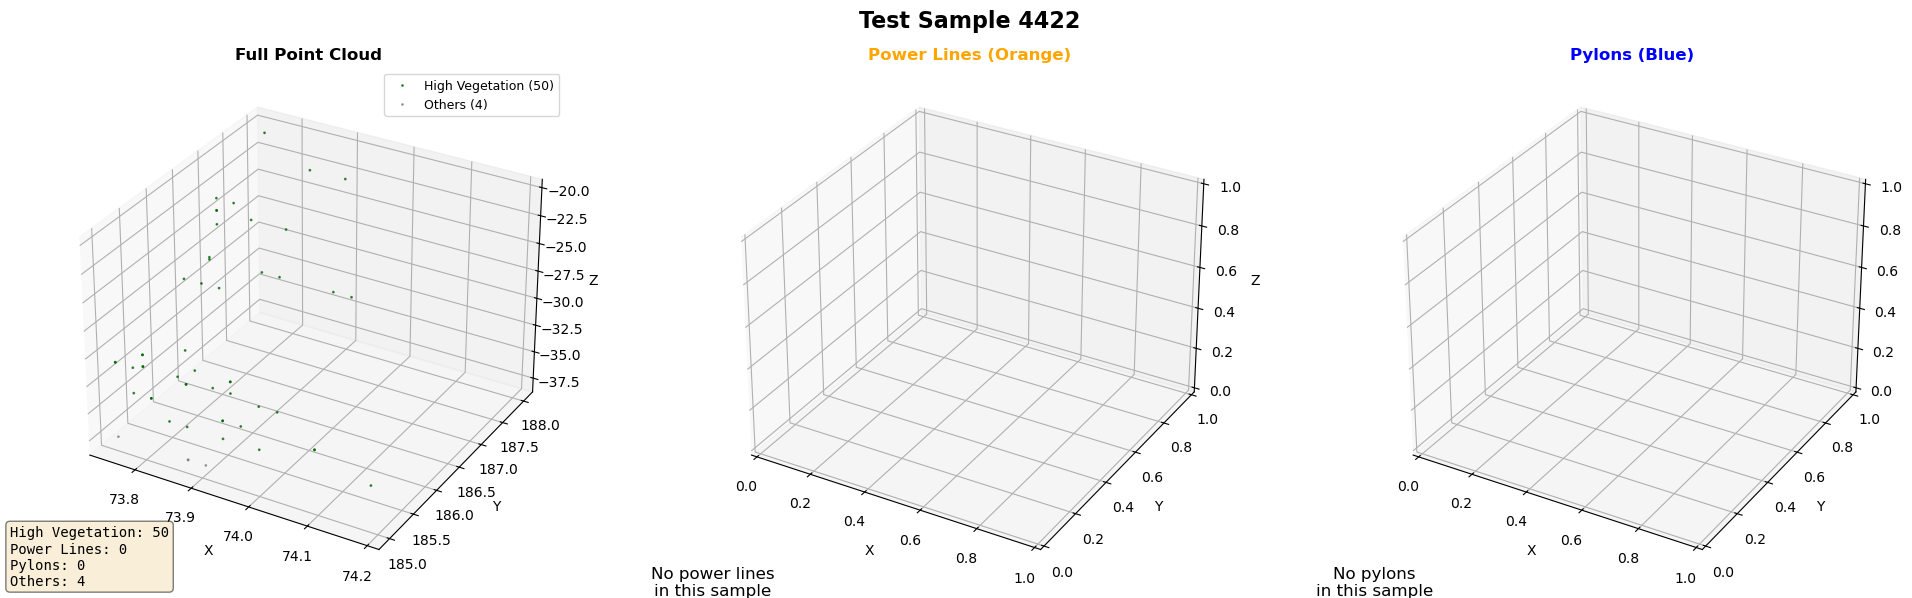


Visualizing sample 3/20 (index: 2916)
Saved: test_visualizations/sample_002916.png


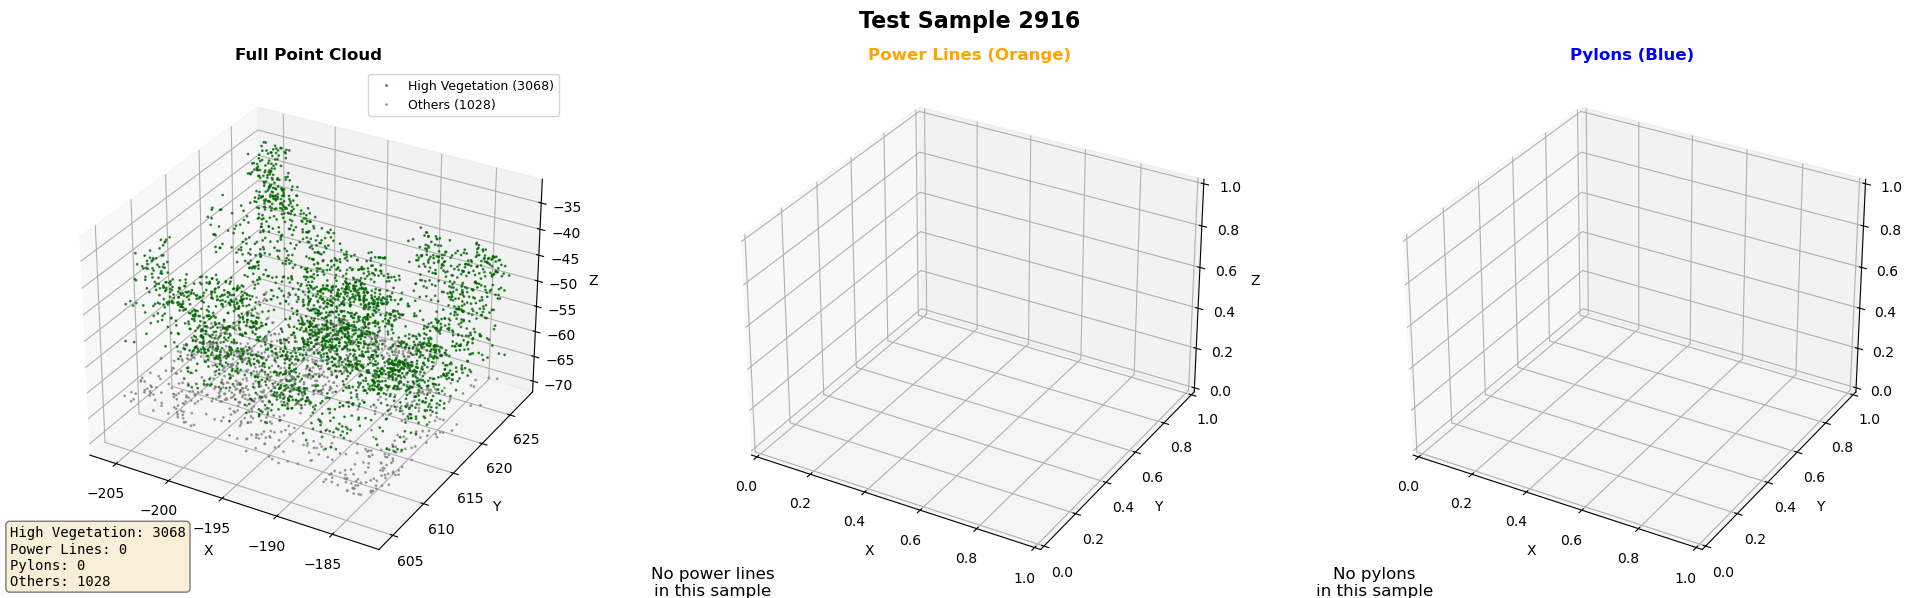


Visualizing sample 4/20 (index: 3062)
Saved: test_visualizations/sample_003062.png


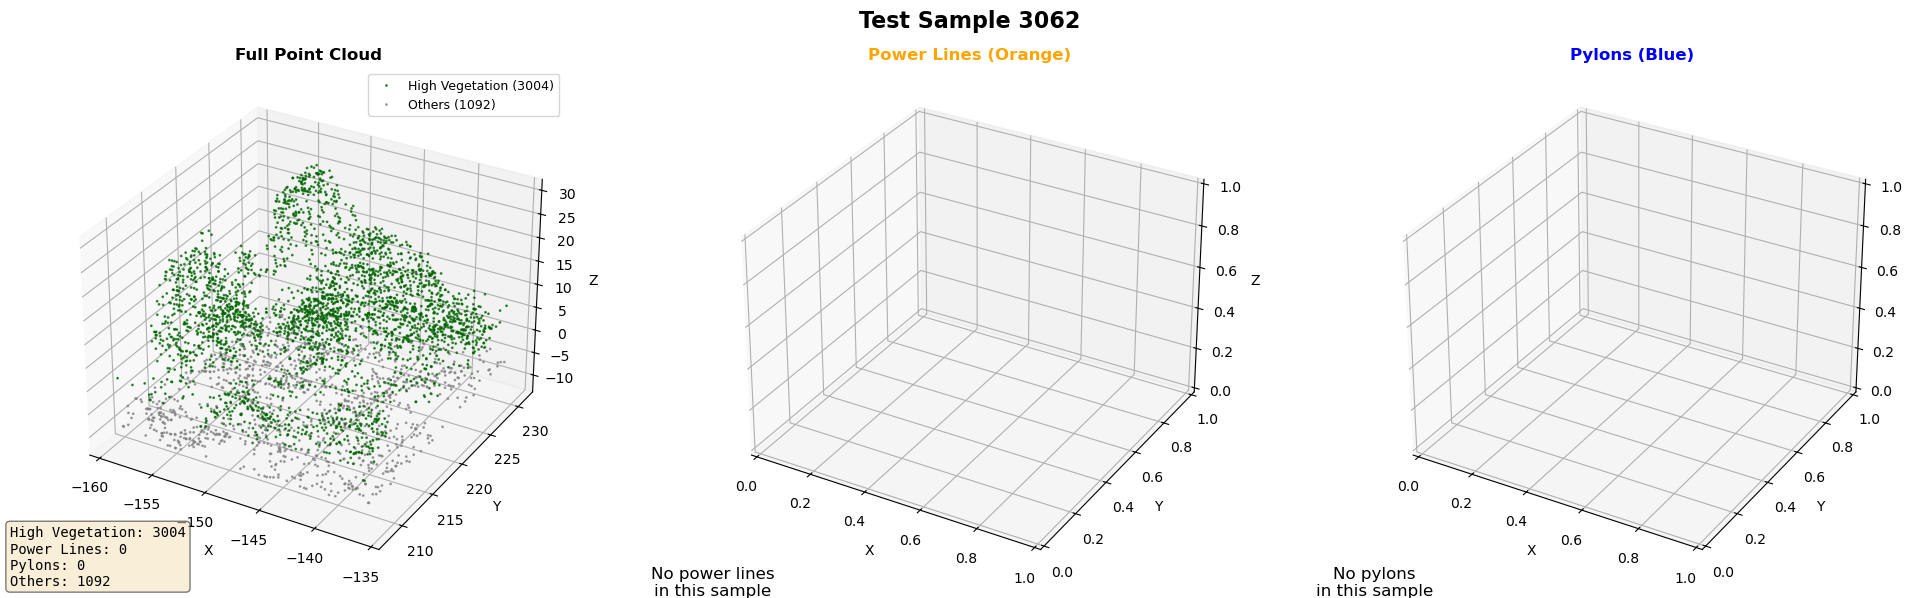


Visualizing sample 5/20 (index: 4626)
Saved: test_visualizations/sample_004626.png


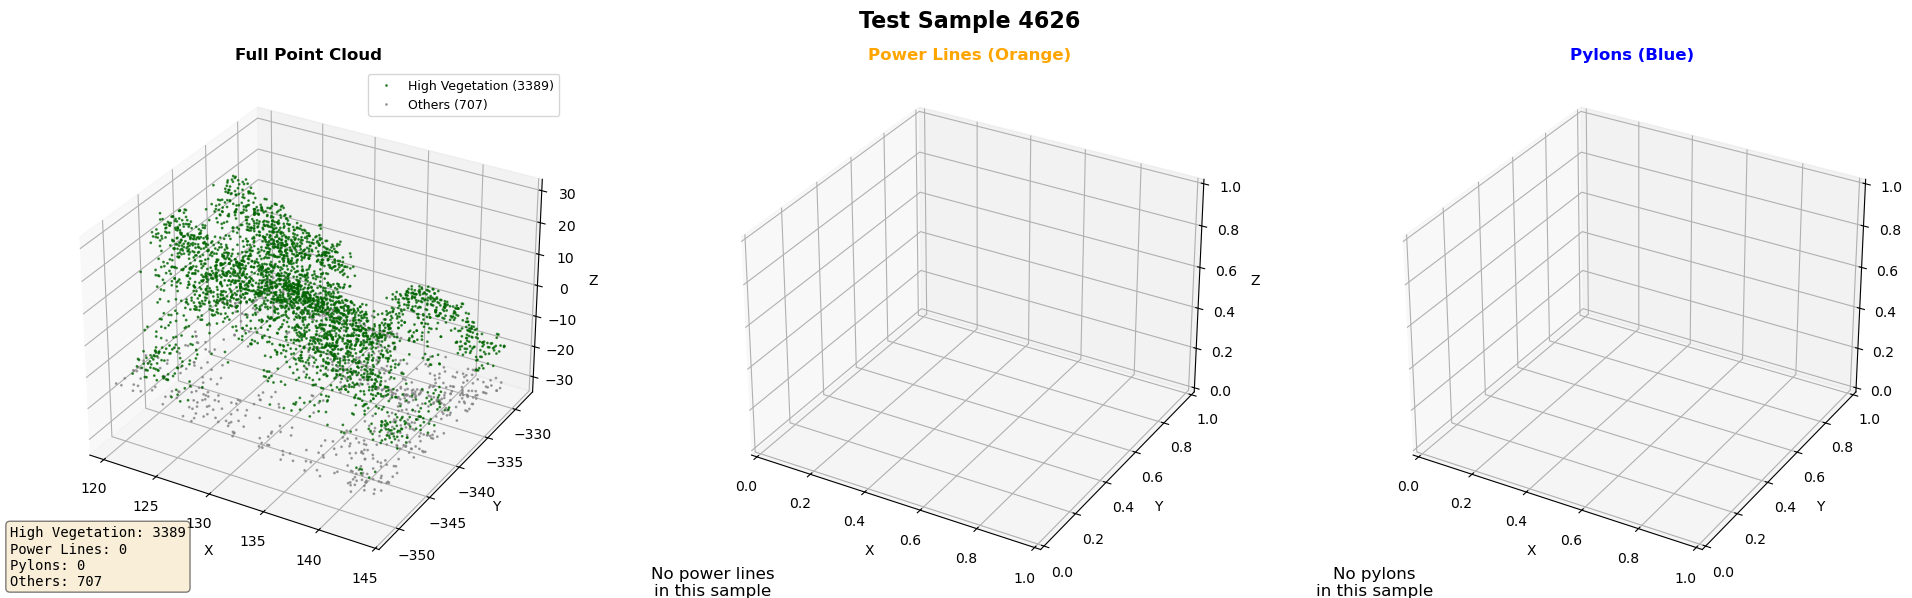


Visualizing sample 6/20 (index: 1805)
Saved: test_visualizations/sample_001805.png


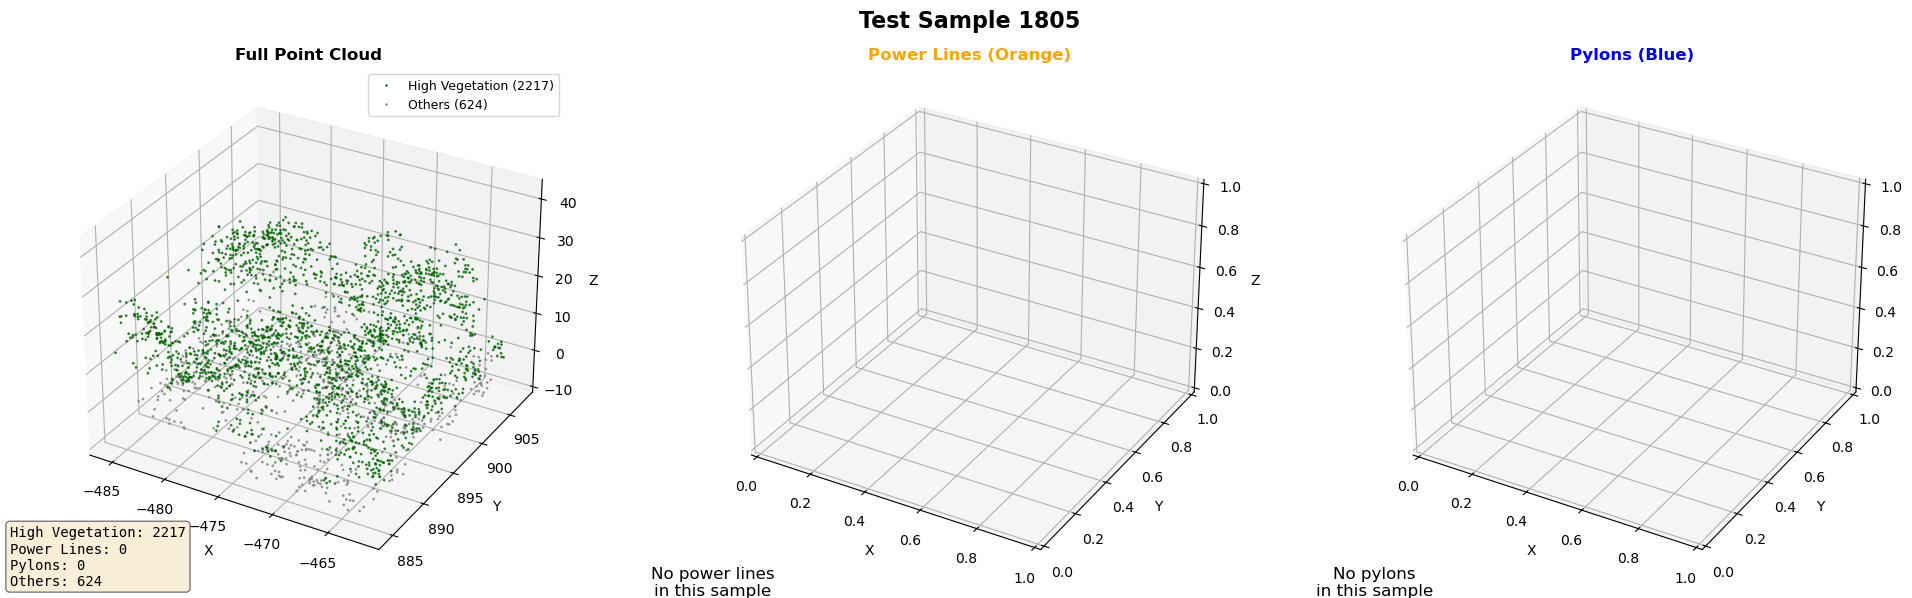


Visualizing sample 7/20 (index: 4875)
Saved: test_visualizations/sample_004875.png


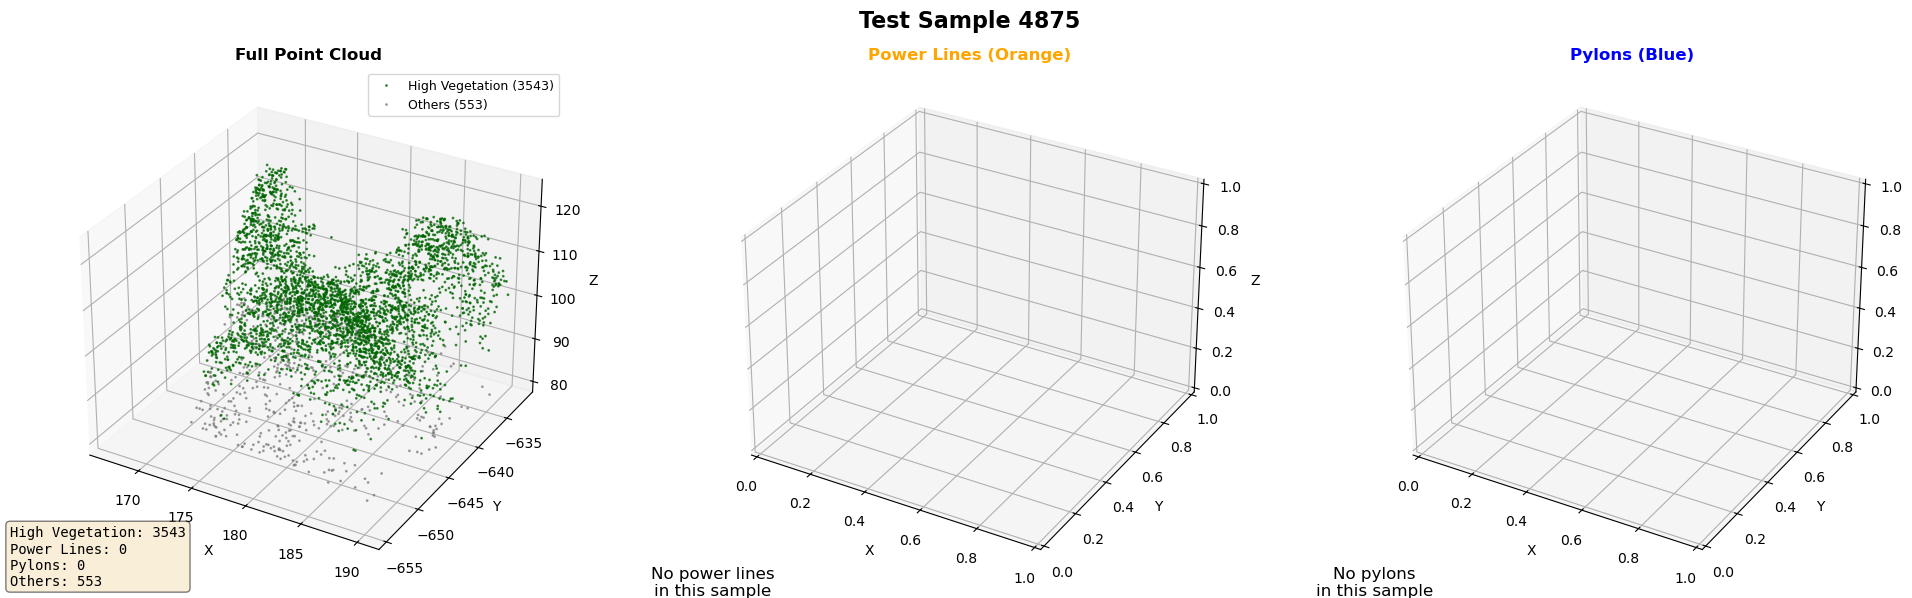


Visualizing sample 8/20 (index: 1800)
Saved: test_visualizations/sample_001800.png


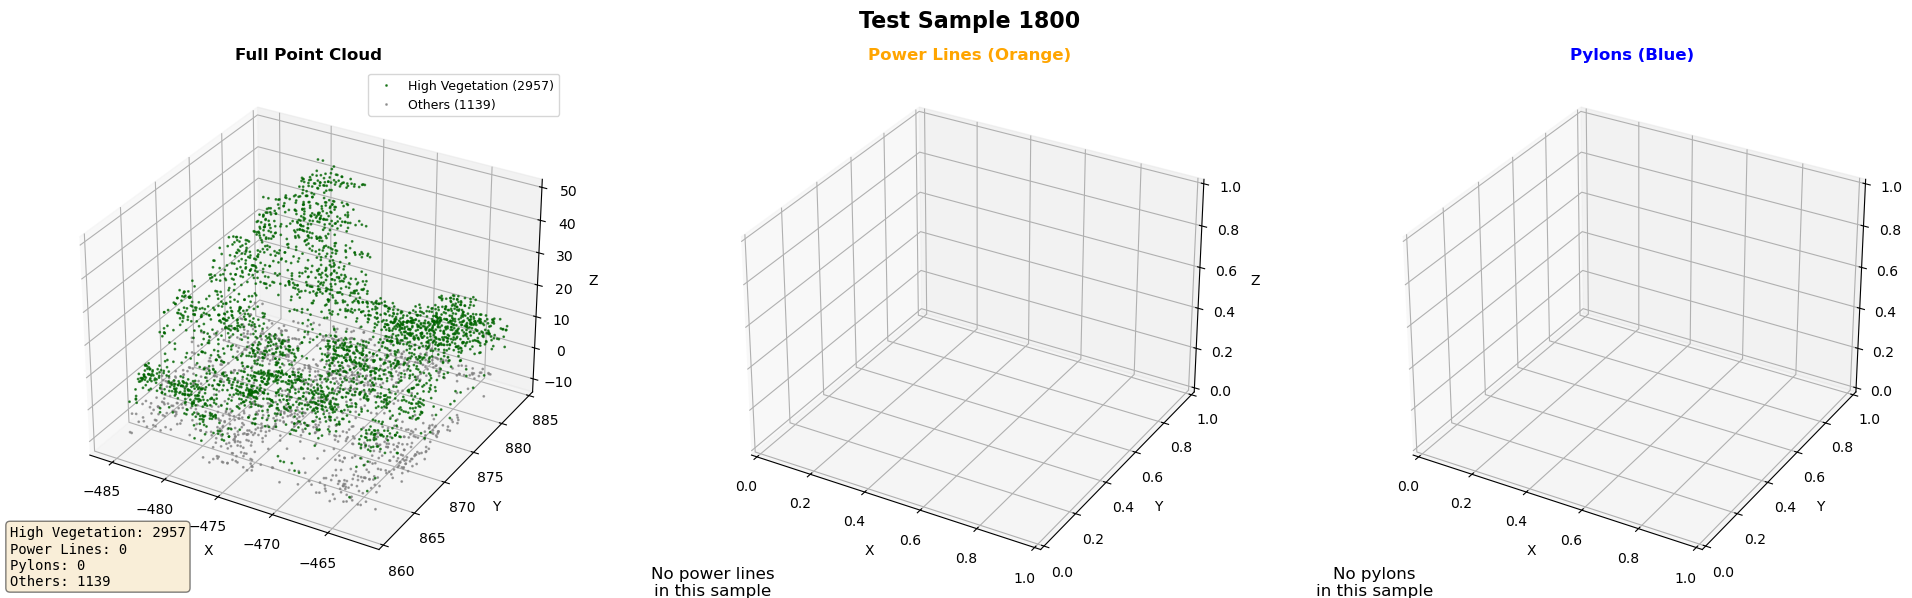


Visualizing sample 9/20 (index: 3512)
Saved: test_visualizations/sample_003512.png


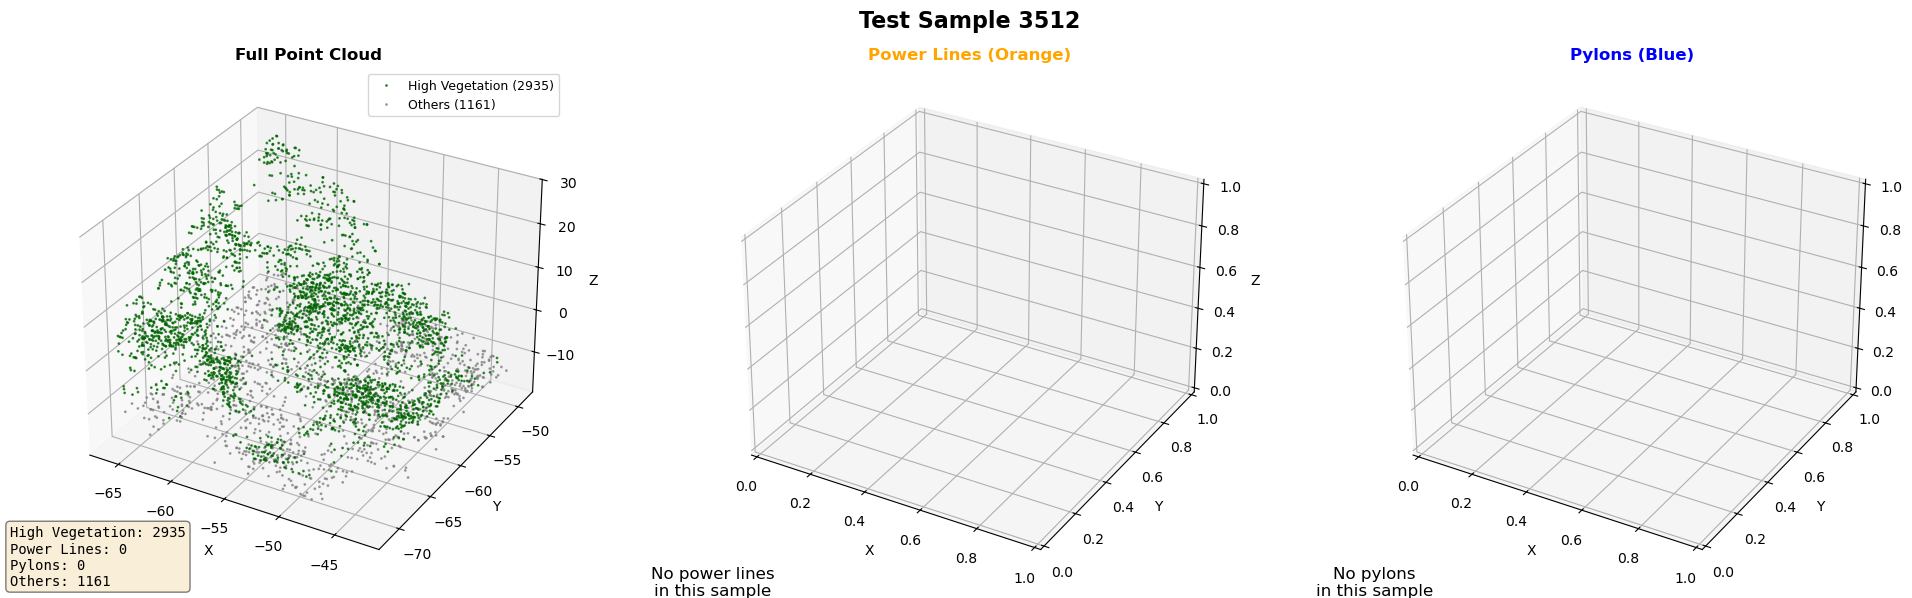


Visualizing sample 10/20 (index: 2085)
Saved: test_visualizations/sample_002085.png


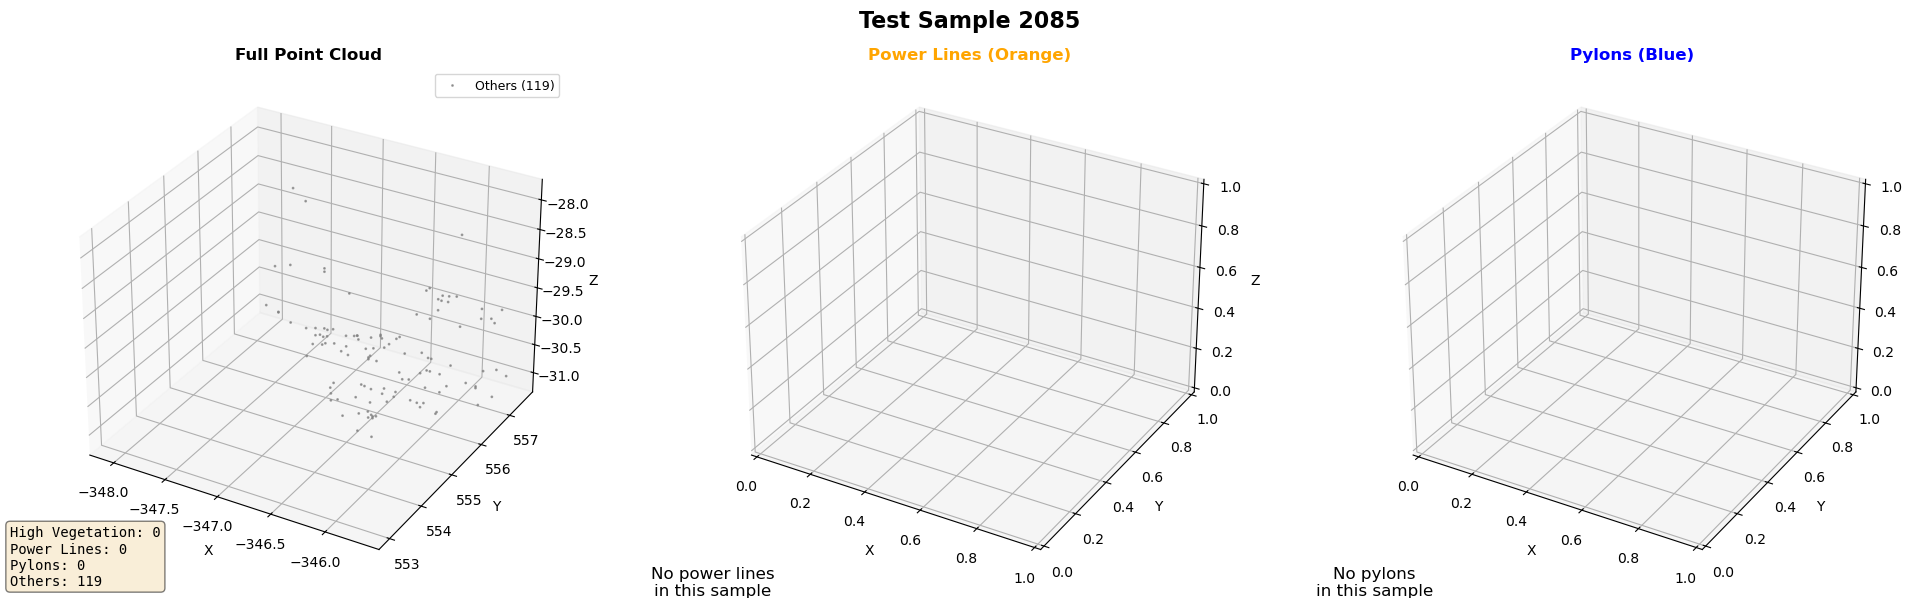


Visualizing sample 11/20 (index: 1086)
Saved: test_visualizations/sample_001086.png


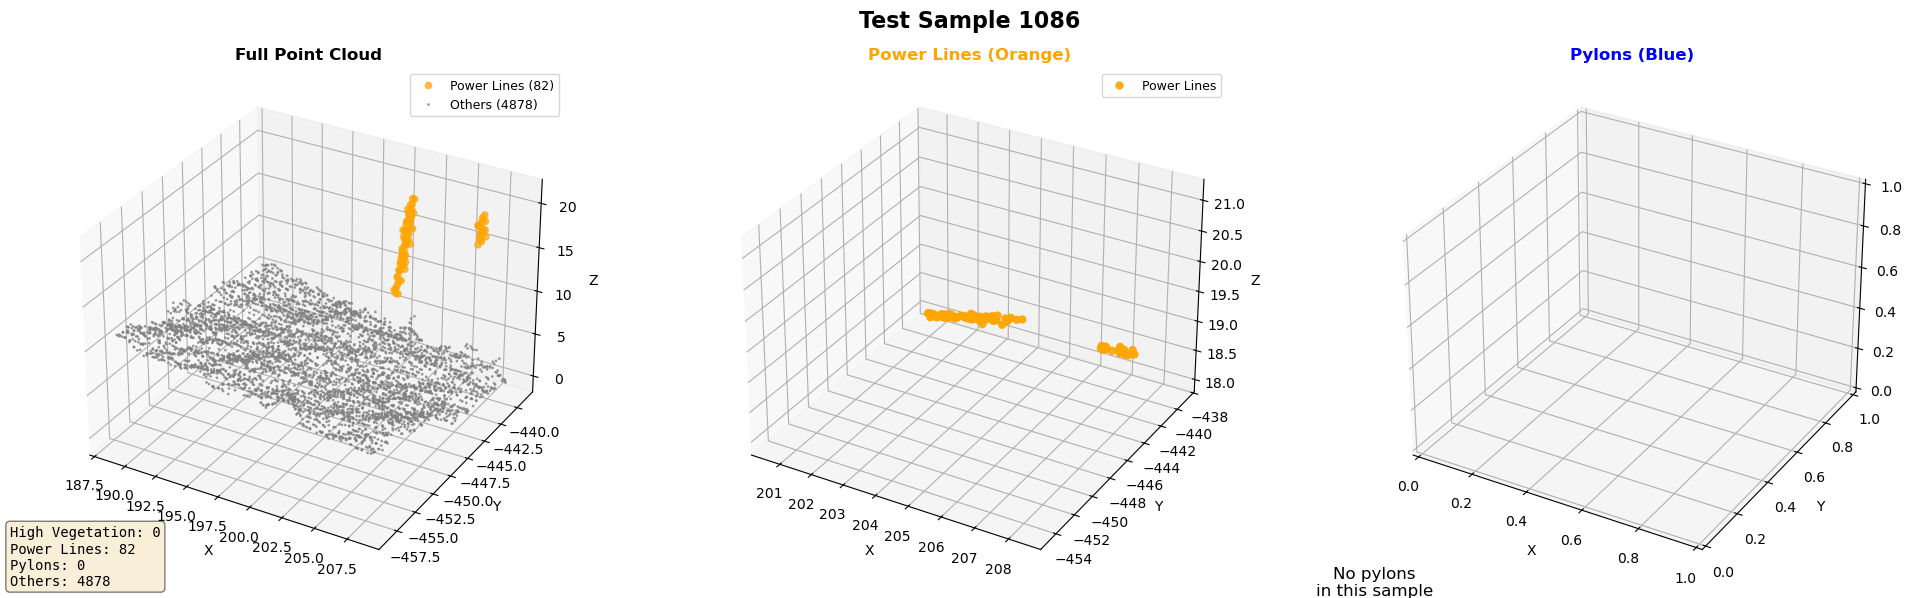


Visualizing sample 12/20 (index: 661)
Saved: test_visualizations/sample_000661.png


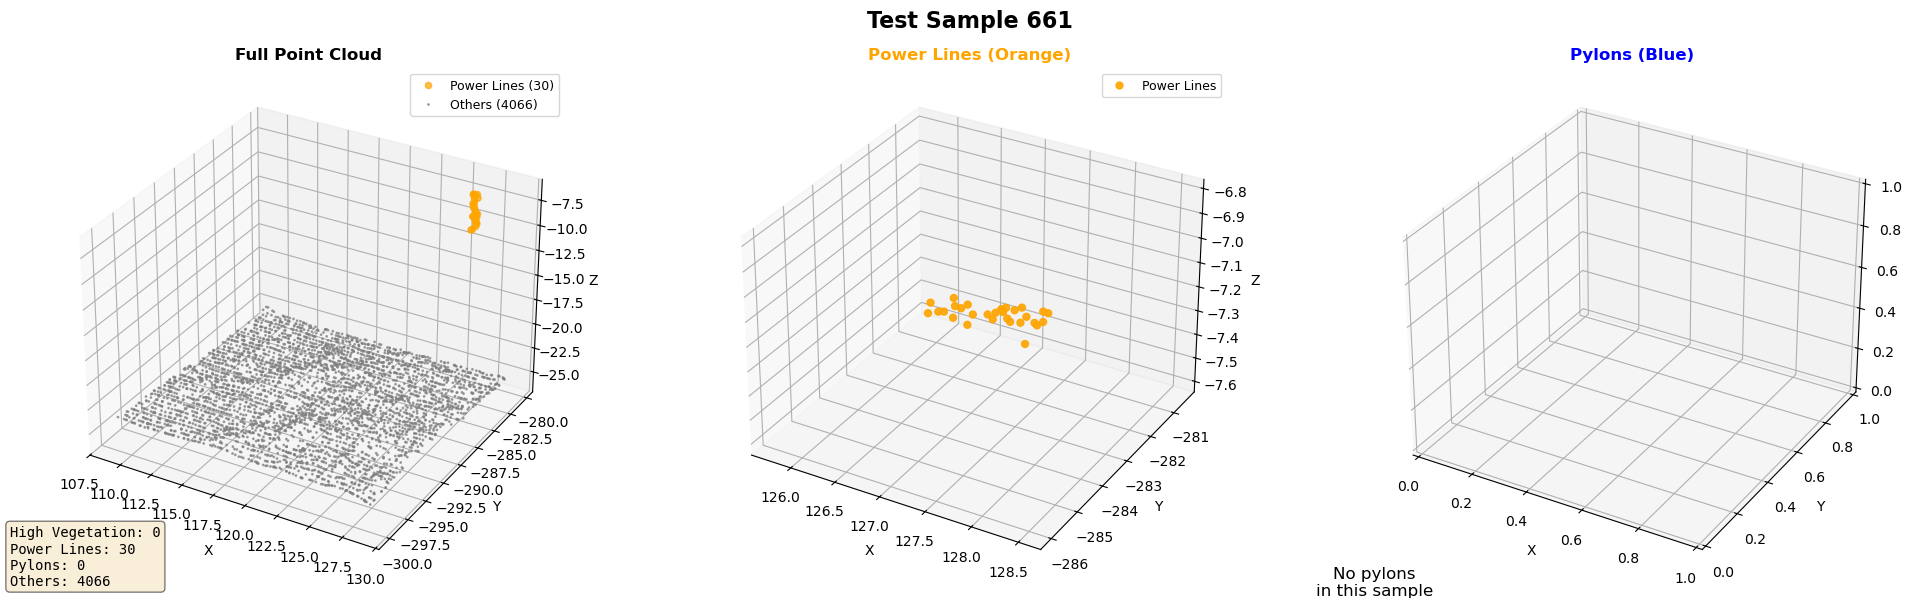


Visualizing sample 13/20 (index: 5452)
Saved: test_visualizations/sample_005452.png


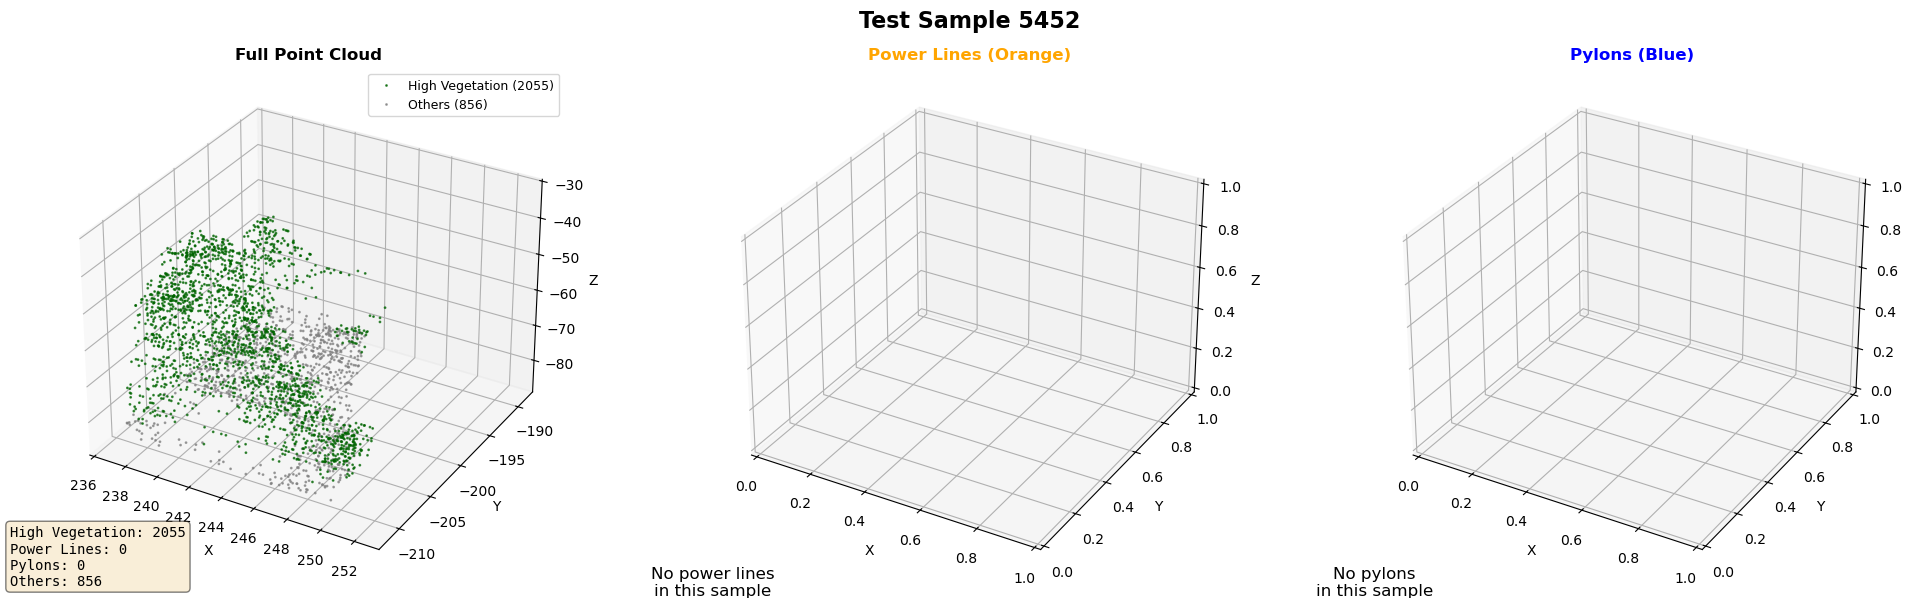


Visualizing sample 14/20 (index: 150)
Saved: test_visualizations/sample_000150.png


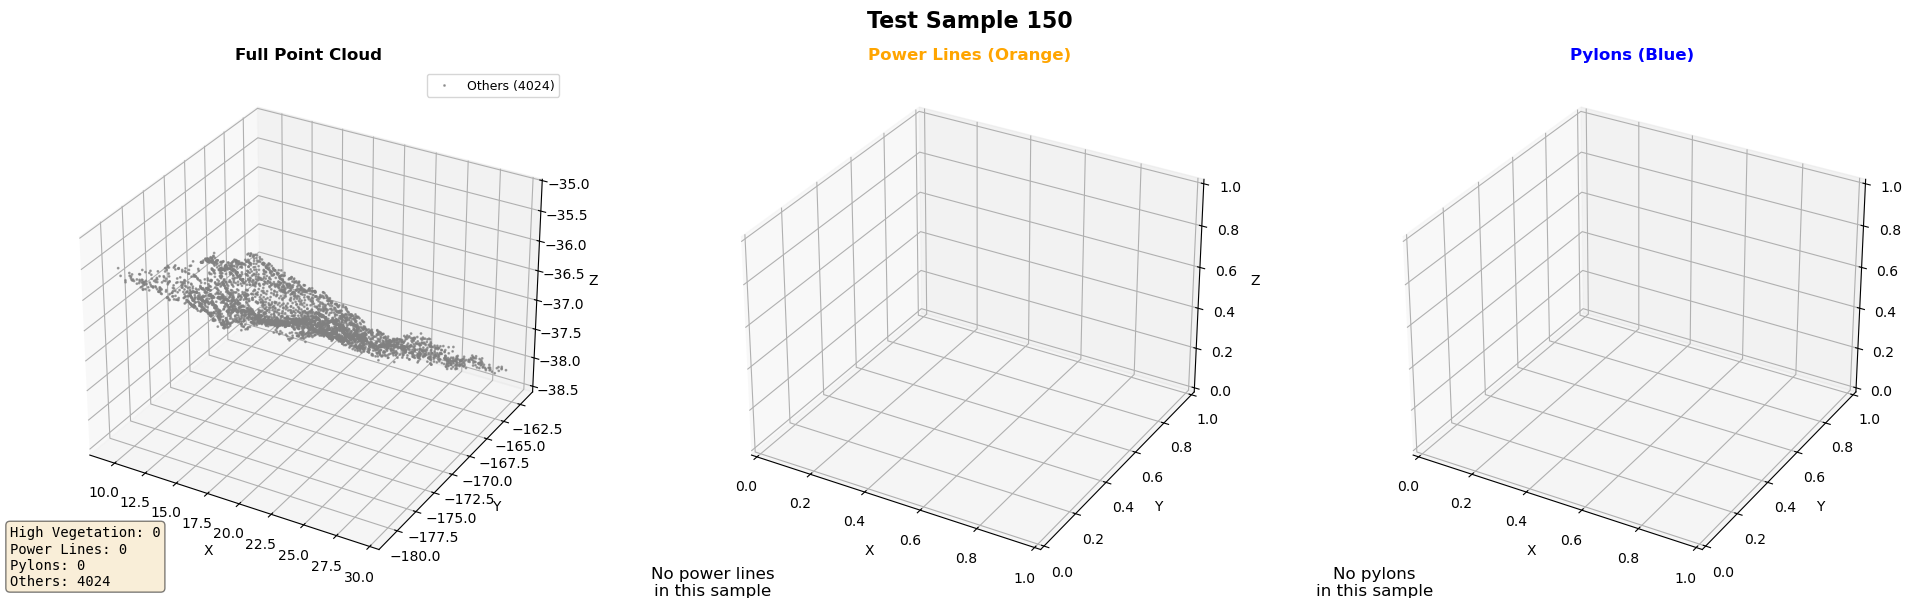


Visualizing sample 15/20 (index: 2735)
Saved: test_visualizations/sample_002735.png


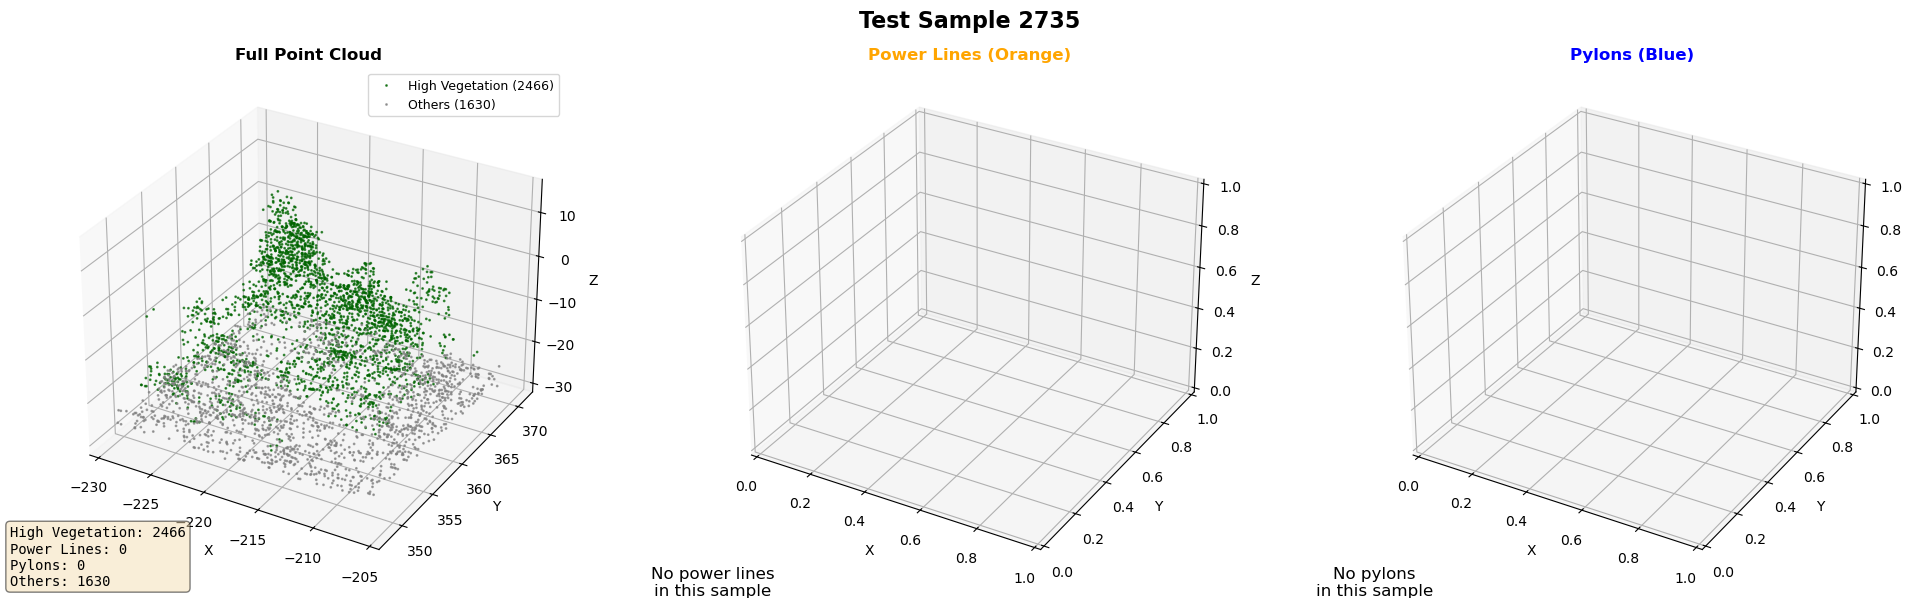


Visualizing sample 16/20 (index: 2836)
Saved: test_visualizations/sample_002836.png


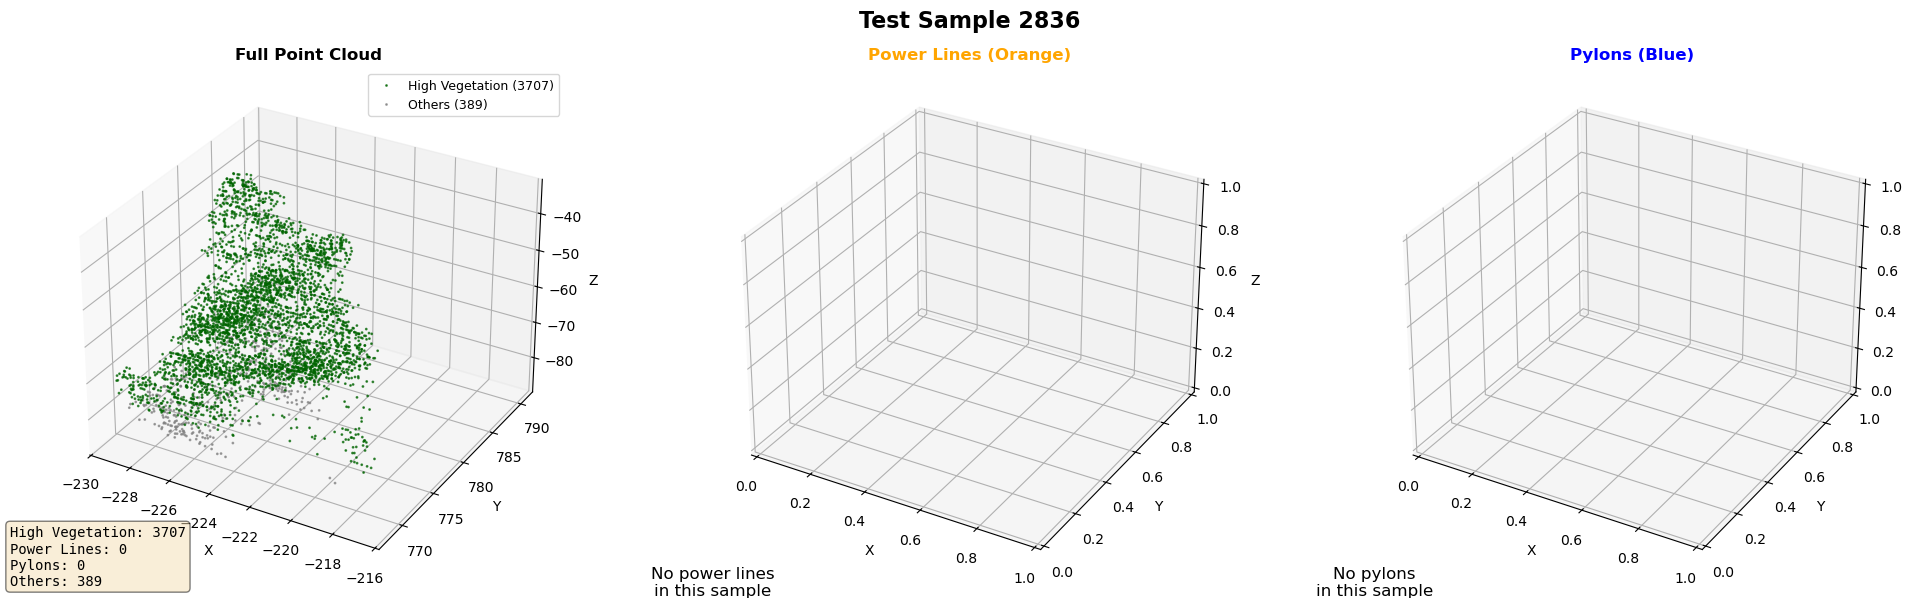


Visualizing sample 17/20 (index: 975)
Saved: test_visualizations/sample_000975.png


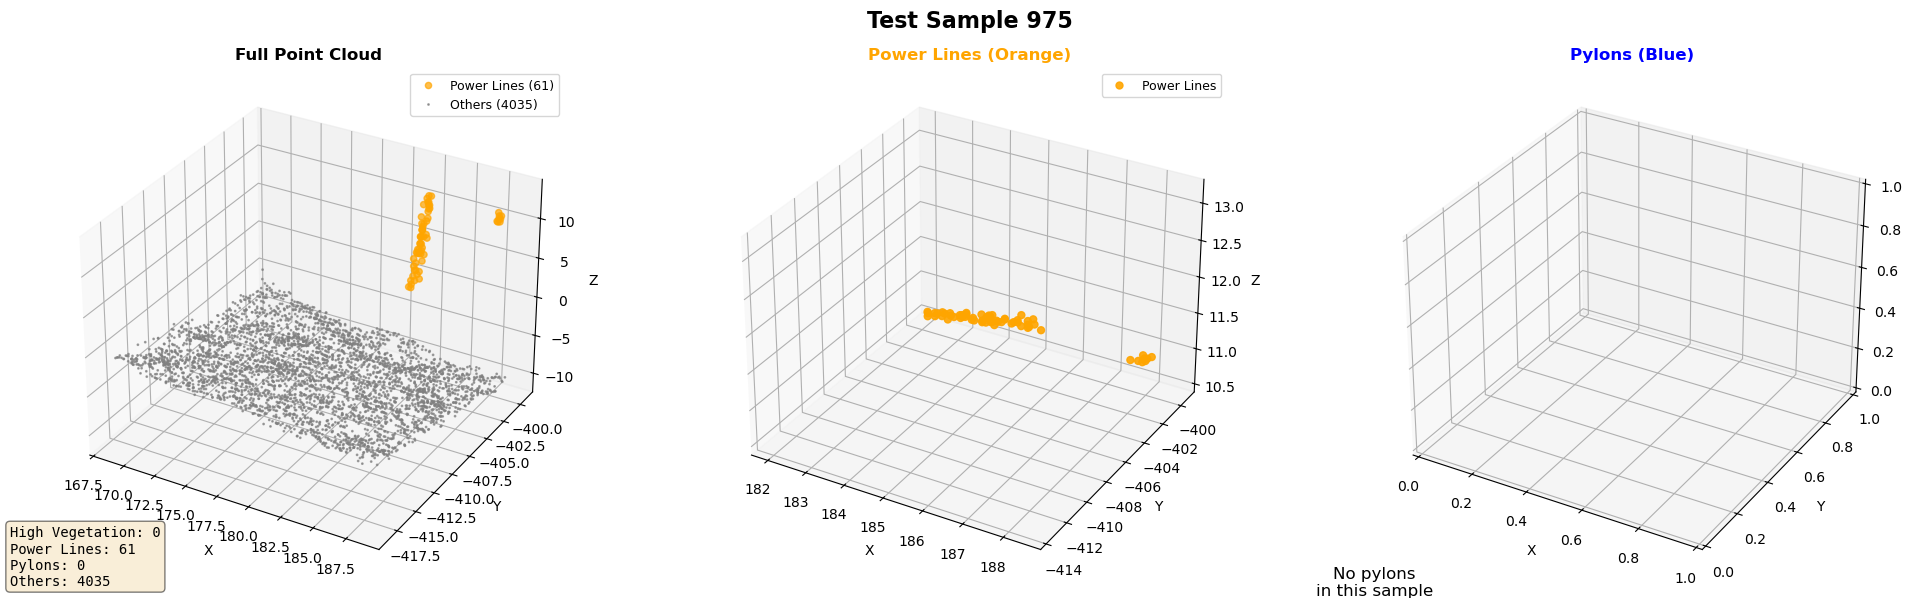


Visualizing sample 18/20 (index: 4163)
Saved: test_visualizations/sample_004163.png


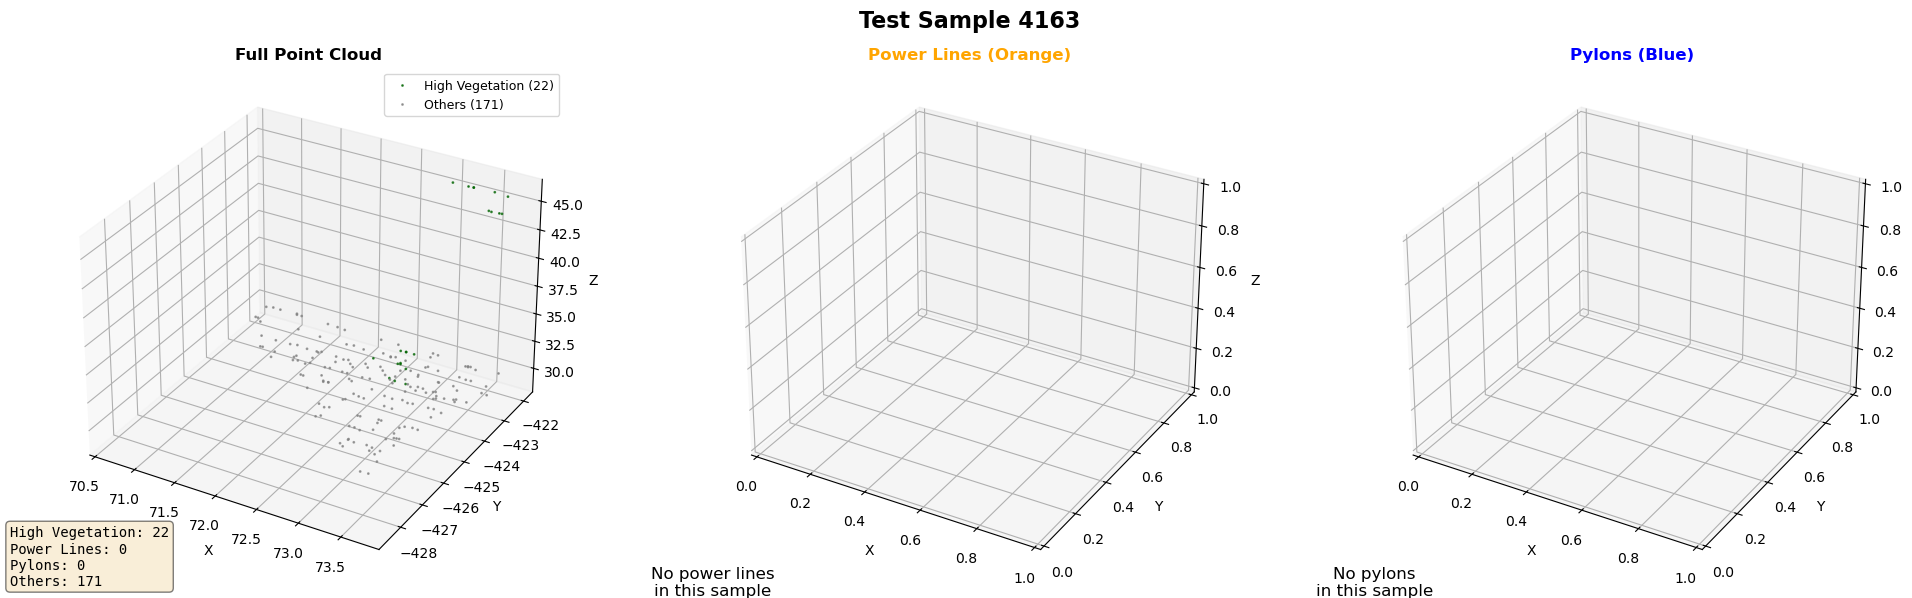


Visualizing sample 19/20 (index: 5382)
Saved: test_visualizations/sample_005382.png


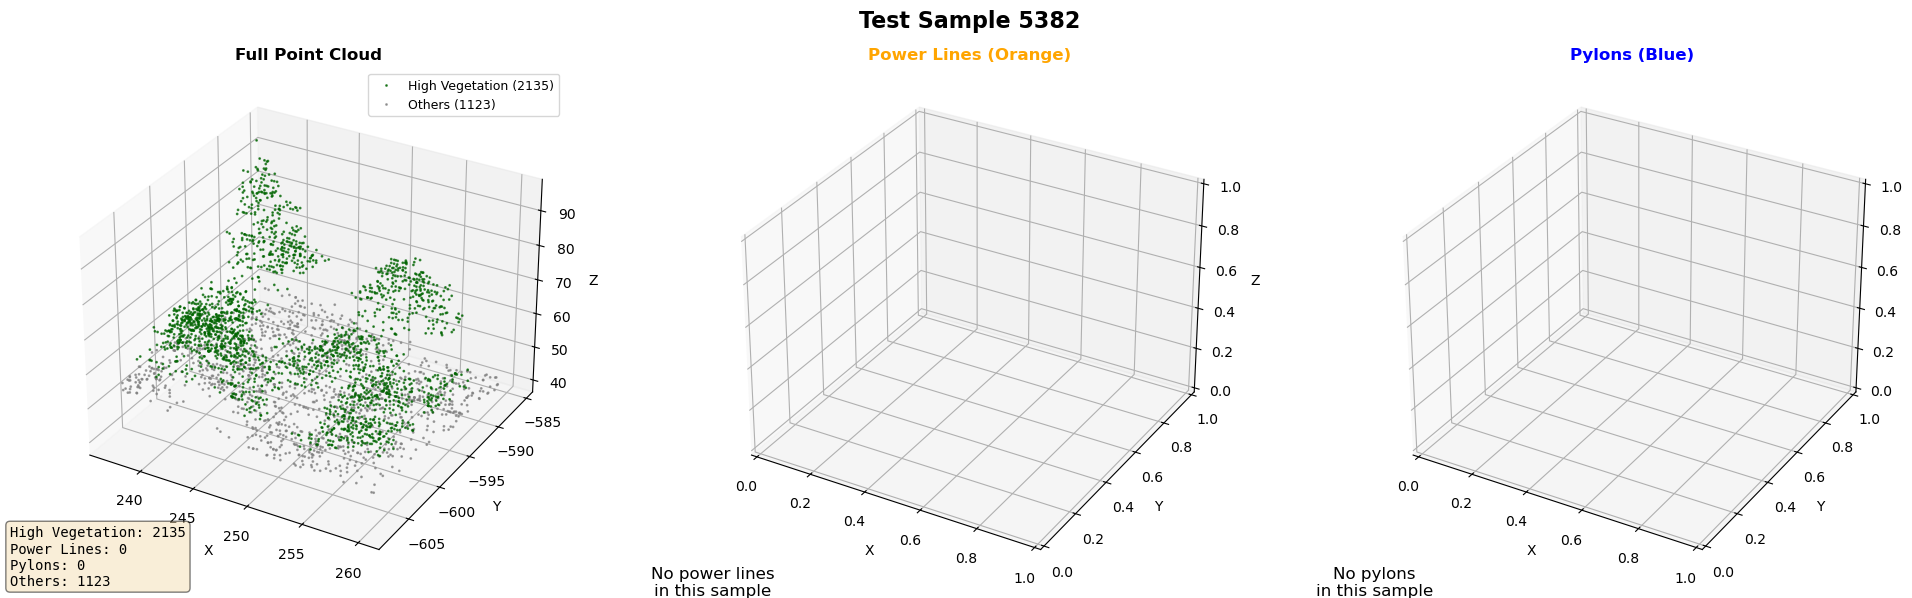


Visualizing sample 20/20 (index: 3372)
Saved: test_visualizations/sample_003372.png


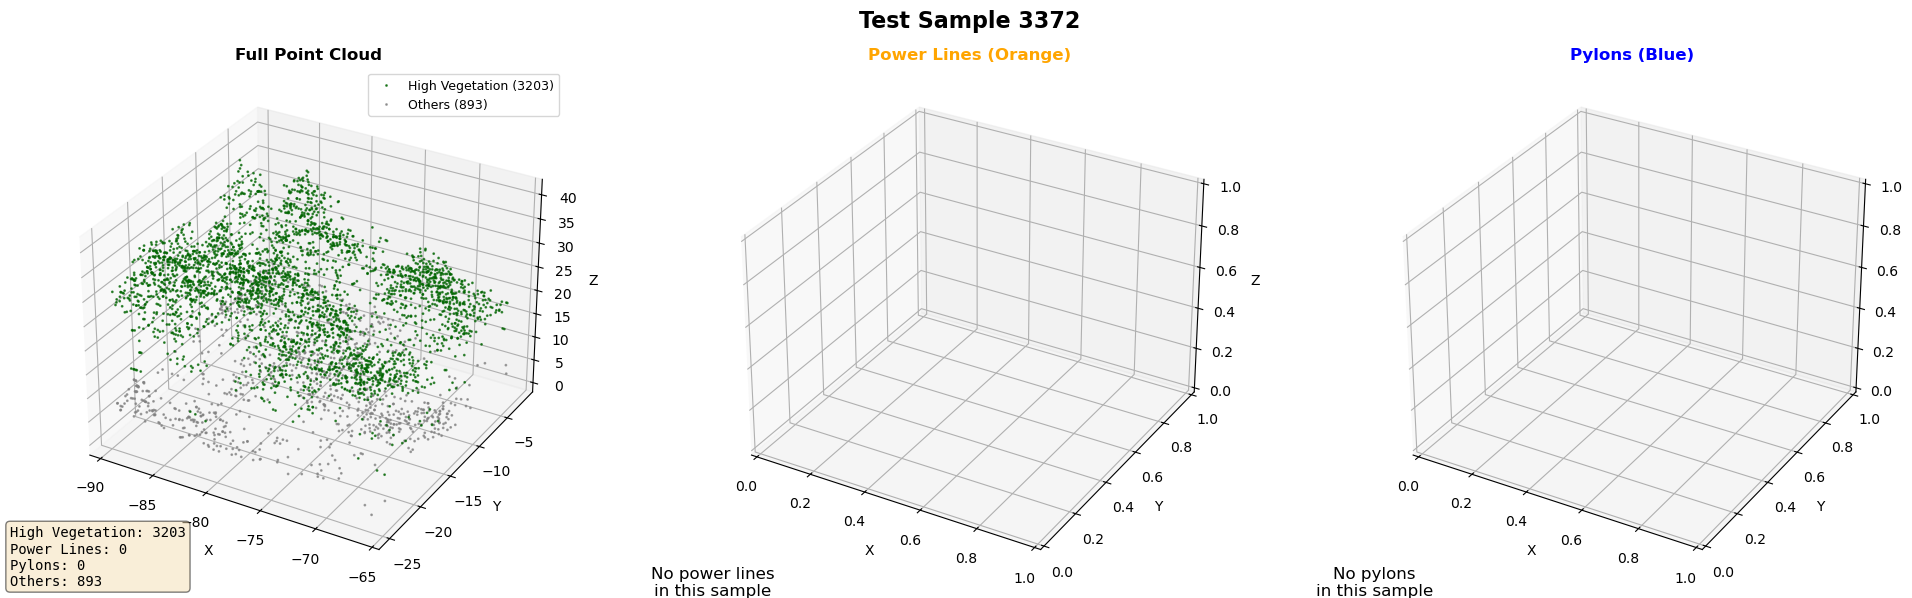


Visualization complete!
All images saved to: test_visualizations/


In [17]:
print(f"Generating visualizations for {len(selected_indices)} samples...\n")

for i, idx in enumerate(selected_indices):
    print(f"\nVisualizing sample {i+1}/{len(selected_indices)} (index: {idx})")
    
    # Load sample
    sample = torch.load(test_samples[idx], weights_only=False)
    
    # Create visualization
    if CONFIG['save_images']:
        save_path = f"{CONFIG['output_dir']}/sample_{idx:06d}.png"
    else:
        save_path = None
    
    visualize_sample(idx, sample, save_path)

print(f"\nVisualization complete!")
if CONFIG['save_images']:
    print(f"All images saved to: {CONFIG['output_dir']}/")

## 8. Class Distribution Pie Chart

Class distribution saved to test_visualizations/class_distribution.png


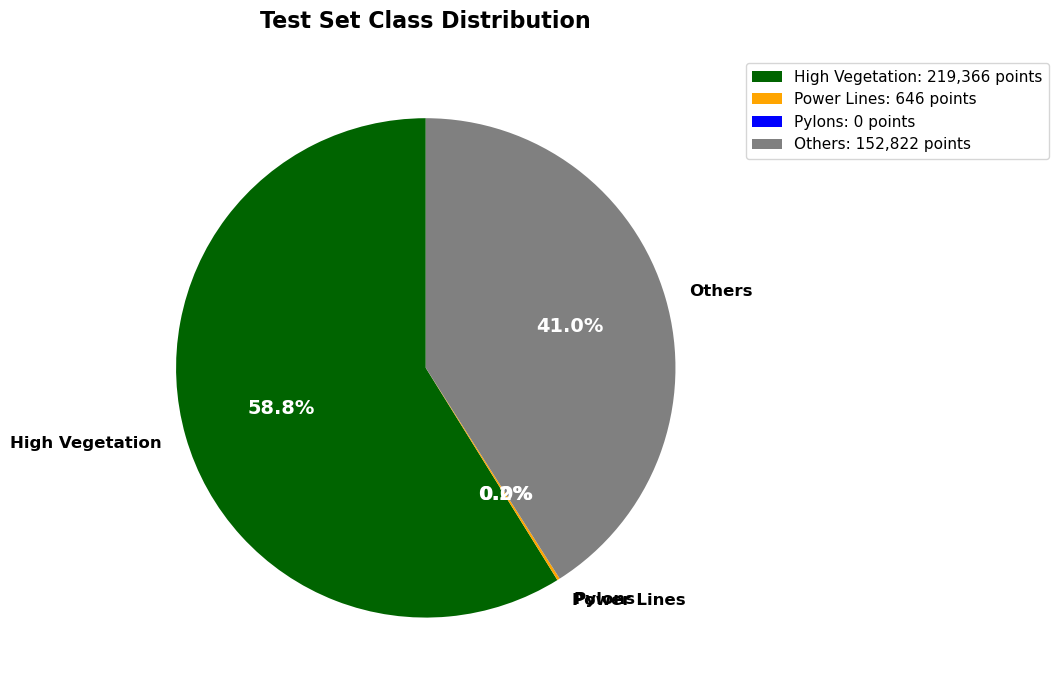

In [18]:
# Create pie chart of class distribution
fig, ax = plt.subplots(figsize=(10, 7))

# Calculate percentages
percentages = (class_counts / total_points) * 100

# Create pie chart
wedges, texts, autotexts = ax.pie(
    class_counts, 
    labels=CLASS_NAMES, 
    colors=CLASS_COLORS,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12, 'weight': 'bold'}
)

# Make percentage text white for visibility
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(14)

ax.set_title('Test Set Class Distribution', fontsize=16, fontweight='bold', pad=20)

# Add legend with counts
legend_labels = [f"{name}: {int(count):,} points" for name, count in zip(CLASS_NAMES, class_counts)]
ax.legend(legend_labels, loc='upper left', bbox_to_anchor=(1, 1), fontsize=11)

plt.tight_layout()

if CONFIG['save_images']:
    plt.savefig(f"{CONFIG['output_dir']}/class_distribution.png", dpi=CONFIG['dpi'], bbox_inches='tight')
    print(f"Class distribution saved to {CONFIG['output_dir']}/class_distribution.png")

plt.show()

## 9. Browse Specific Sample

Browsing sample at index 0
File: sample_000000.pt


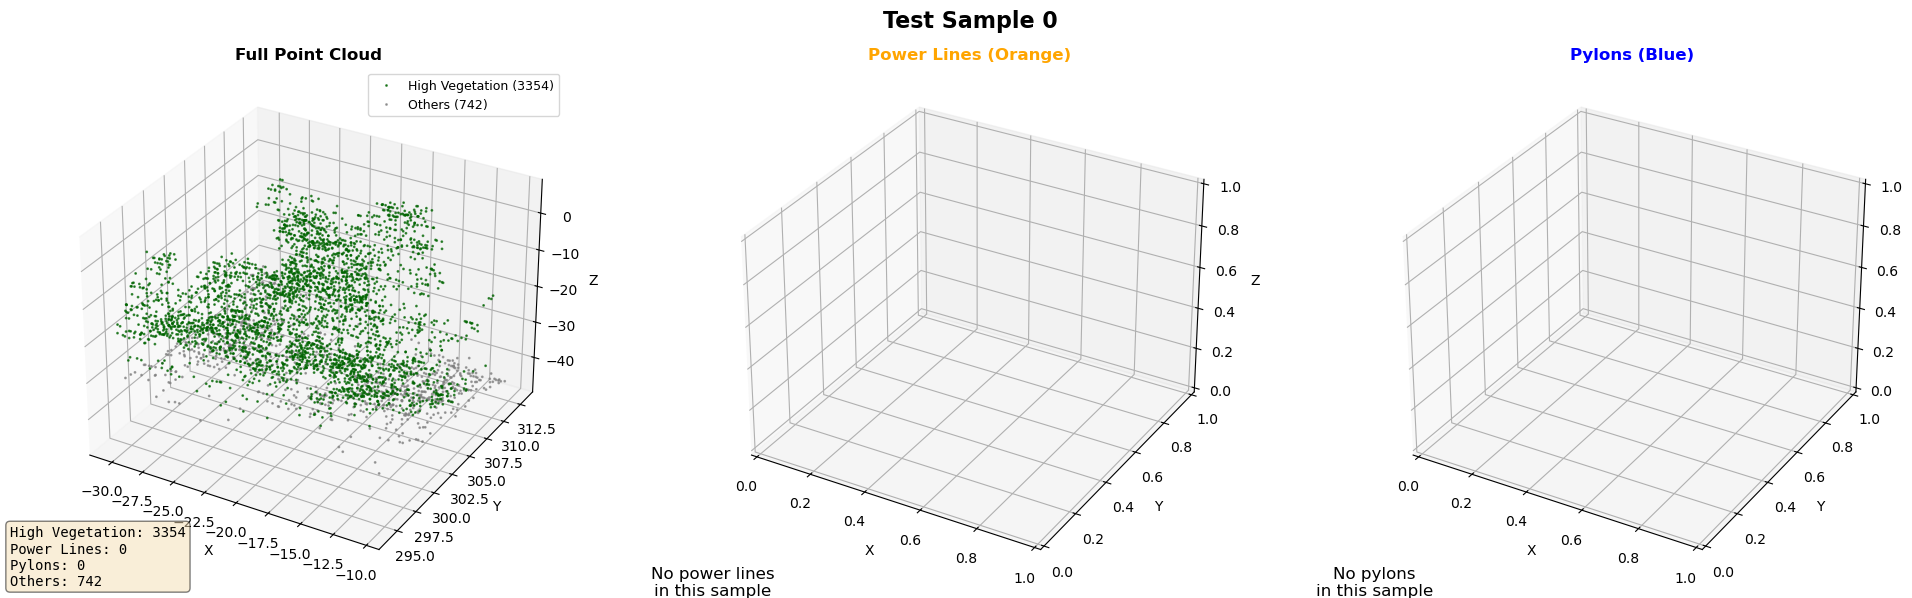


Detailed Statistics:
  Total points: 4,096
  Point cloud bounds:
    X: [-30.38, -10.50]
    Y: [294.00, 313.00]
    Z: [-46.15, 5.27]

  Class breakdown:
    High Vegetation: 3,354 (81.88%)
    Power Lines: 0 (0.00%)
    Pylons: 0 (0.00%)
    Others: 742 (18.12%)


In [19]:
# Interactive: Change this index to browse different samples
BROWSE_INDEX = 0  # Change this to any index from 0 to len(test_samples)-1

print(f"Browsing sample at index {BROWSE_INDEX}")
print(f"File: {test_samples[BROWSE_INDEX].name}")

sample = torch.load(test_samples[BROWSE_INDEX], weights_only=False)
visualize_sample(BROWSE_INDEX, sample, save_path=None)

# Print detailed stats
labels = (sample['semantic_labels'].squeeze() - 1).numpy()
points = sample['input_pcd'].numpy()

print(f"\nDetailed Statistics:")
print(f"  Total points: {len(points):,}")
print(f"  Point cloud bounds:")
print(f"    X: [{points[:, 0].min():.2f}, {points[:, 0].max():.2f}]")
print(f"    Y: [{points[:, 1].min():.2f}, {points[:, 1].max():.2f}]")
print(f"    Z: [{points[:, 2].min():.2f}, {points[:, 2].max():.2f}]")
print(f"\n  Class breakdown:")
for i, name in enumerate(CLASS_NAMES):
    count = (labels == i).sum()
    pct = 100 * count / len(labels)
    print(f"    {name}: {count:,} ({pct:.2f}%)")

## 10. Find Best Examples

In [20]:
# Find samples with most power lines
print("Finding samples with most power infrastructure...\n")

powerline_counts = []
pylon_counts = []

for idx in tqdm(range(min(200, len(test_samples))), desc="Scanning"):
    sample = torch.load(test_samples[idx], weights_only=False)
    labels = (sample['semantic_labels'].squeeze() - 1).numpy()
    
    pl_count = (labels == 1).sum()
    py_count = (labels == 2).sum()
    
    powerline_counts.append((idx, pl_count))
    pylon_counts.append((idx, py_count))

# Sort and display top samples
powerline_counts.sort(key=lambda x: x[1], reverse=True)
pylon_counts.sort(key=lambda x: x[1], reverse=True)

print("\nTop 5 samples with most power lines:")
for i, (idx, count) in enumerate(powerline_counts[:5], 1):
    print(f"  {i}. Index {idx}: {count:,} power line points")

print("\nTop 5 samples with most pylons:")
for i, (idx, count) in enumerate(pylon_counts[:5], 1):
    print(f"  {i}. Index {idx}: {count:,} pylon points")

print("\nUpdate BROWSE_INDEX in cell above to visualize these samples!")

Finding samples with most power infrastructure...



Scanning: 100%|██████████| 200/200 [00:00<00:00, 3023.94it/s]


Top 5 samples with most power lines:
  1. Index 60: 271 power line points
  2. Index 166: 209 power line points
  3. Index 59: 202 power line points
  4. Index 165: 195 power line points
  5. Index 61: 129 power line points

Top 5 samples with most pylons:
  1. Index 0: 0 pylon points
  2. Index 1: 0 pylon points
  3. Index 2: 0 pylon points
  4. Index 3: 0 pylon points
  5. Index 4: 0 pylon points

Update BROWSE_INDEX in cell above to visualize these samples!


## Summary

This notebook provides:

1. ✅ **Test set exploration** - Browse and analyze test samples
2. ✅ **3D visualizations** - Detailed views of point clouds
3. ✅ **Class distribution** - Understand data composition
4. ✅ **Filtered viewing** - Find samples with specific classes
5. ✅ **Best examples** - Identify samples with most power infrastructure

**Key Features:**
- No model inference needed (fast!)
- Focus on power lines and pylons
- Easy to browse specific samples
- Save visualizations for presentations

**Tips:**
- Change `filter_by_class` to 'powerlines', 'pylons', or 'both' to filter samples
- Update `BROWSE_INDEX` to view specific samples
- Increase `num_samples` to generate more visualizations
- All images saved to `test_visualizations/` folder